In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training,
                   run_training_loop, plot_training_log)

In [2]:
# ── What to train ─────────────────────────────────────────────────────────────
train_task = 'pure'

# Frequency grid context: includes all task types the animal may encounter,
# so the network learns to encode across the full frequency range.
task_list  = ['pure', 'harmonic', 'wn']

# ── Training schedule ────────────────────────────────────────────────────────
n_steps         = 15000   # total training batches
k               = 200     # evaluate and save every k batches
seed            = 0
eval_with_noise = True  # if True, evaluation uses same noise as training

# ── Save location ────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR / train_task) + '/'

In [3]:
state, cfg = setup_training(train_task, task_list, n_steps, k, seed, save_dir)

task_list : ['pure', 'harmonic', 'wn']
train_task: pure
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\GitHub\tone_generalize\code\results\pure\pure_0_lr5e-05_bs128_noise0.5_nrnn128


In [4]:
state, log = run_training_loop(state, train_task, task_list, cfg, eval_with_noise=eval_with_noise)

step    200  loss=0.2322  hit=0.02  FA=0.03
step    400  loss=0.2141  hit=0.09  FA=0.05
step    600  loss=0.2039  hit=0.18  FA=0.05
step    800  loss=0.1805  hit=0.34  FA=0.25
step   1000  loss=0.1687  hit=0.57  FA=0.38
step   1200  loss=0.1315  hit=0.82  FA=0.46
step   1400  loss=0.0944  hit=0.57  FA=0.11
step   1600  loss=0.0731  hit=0.56  FA=0.04
step   1800  loss=0.0621  hit=0.44  FA=0.00
step   2000  loss=0.0466  hit=0.54  FA=0.00
step   2200  loss=0.0425  hit=0.59  FA=0.00
step   2400  loss=0.0411  hit=0.56  FA=0.00
step   2600  loss=0.0367  hit=0.73  FA=0.00
step   2800  loss=0.0316  hit=0.66  FA=0.00
step   3000  loss=0.0336  hit=0.71  FA=0.00
step   3200  loss=0.0320  hit=0.72  FA=0.00
step   3400  loss=0.0315  hit=0.68  FA=0.00
step   3600  loss=0.0302  hit=0.80  FA=0.00
step   3800  loss=0.0276  hit=0.80  FA=0.00
step   4000  loss=0.0256  hit=0.81  FA=0.00
step   4200  loss=0.0230  hit=0.87  FA=0.00
step   4400  loss=0.0237  hit=0.86  FA=0.00
step   4600  loss=0.0219  hit=0.

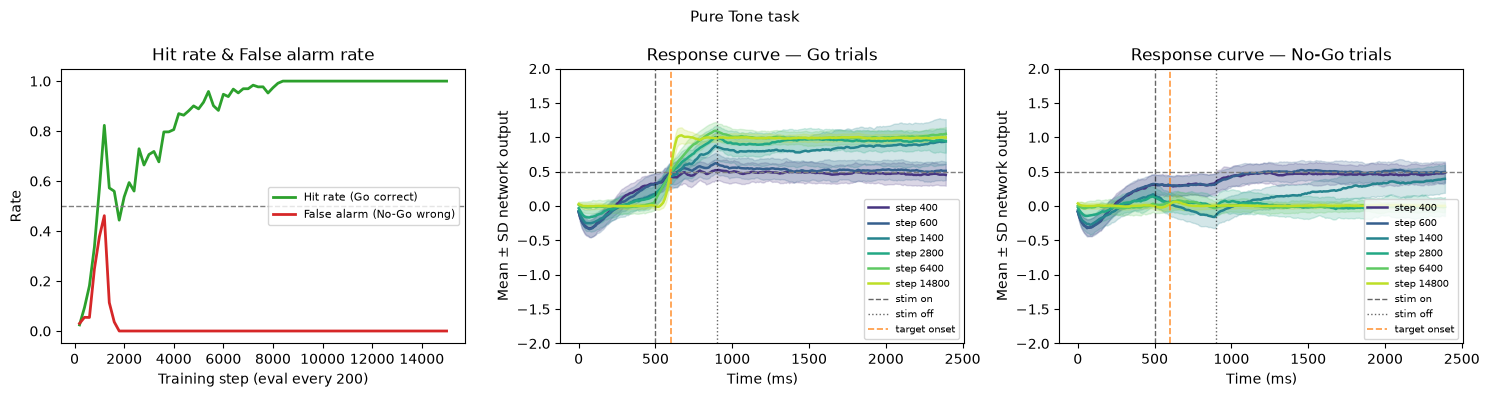

In [5]:
plot_training_log(cfg['save_path'], title='Pure Tone task', last_snap_step=15000);